# In-memory preprocessing of all event pairs

This notebook recreates the pair features and labels from `src/scripts/preprocessing.py` for **every raw event as an anchor**. It keeps two separate results in memory: `events_df` and `false_events_df`. It does not write Parquet files or configure logging.

The source coincidence limits are unchanged: on-time partners have `0 < dt <= T` (2 ms), and off-time partners have `T < dt <= 11*T` (up to 22 ms). All events are considered as anchors, in chronological order. Each earlier-later combination is emitted once, so candidate pairs can overlap.

This processes the complete raw dataset and can produce large DataFrames. The candidate-count cell reports the expected row counts before pair features are built. Both input tables must be row-aligned and have columns in the expected order: five event columns (`time, energy, x, y, z`) and three truth columns (`label, pair_id, label_name`).

In [1]:
# 1. Import Required Libraries
from pathlib import Path

import numpy as np
import pandas as pd

# Support kernels started from either the repository root or notebooks/.
RAW_DIR_CANDIDATES = [Path("data/raw/training"), Path("../data/raw/training")]
RAW_DIR = next(
    (
        candidate
        for candidate in RAW_DIR_CANDIDATES
        if (candidate / "events.parquet").is_file()
        and (candidate / "truth.parquet").is_file()
    ),
    RAW_DIR_CANDIDATES[0],
)

PAIR_THRESHOLD_NS = 2_000_000  # 2 ms, matching preprocessing.py
N_OFF_WINDOWS = 10
BLOCK_DURATION_NS = 60 * 60 * 1_000_000_000  # Example: 1 hour; tune for the run
DETECTOR_RADIUS_M = 1.5
DETECTOR_HALF_HEIGHT_M = 1.55

RAW_EVENT_COLUMNS = ["time", "energy", "x", "y", "z"]
RAW_TRUTH_COLUMNS = ["label", "pair_id", "label_name"]

RAW_TO_PHYS = {
    "time": "t",
    "energy": "E",
    "x": "x",
    "y": "y",
    "z": "z",
    "r": "r",
    "r2": "r2",
    "phi": "phi",
    "distance": "D",
}

INDIVIDUAL_COLUMNS = (
    [f"{name}_1" for name in RAW_TO_PHYS.values()]
    + [f"{name}_2" for name in RAW_TO_PHYS.values()]
    + ["dwall_1", "dwall_2"]
)
DELTA_COLUMNS = ["dt"] + [
    f"d{name}" for name in RAW_TO_PHYS.values() if name != "t"
] + ["dR"]
COUNT_COLUMNS = [
    "k_window", "dt_shifted", "n_before", "n_on", "n_gap", "n_in_window", "is_dc"
]
FEATURE_COLUMNS = INDIVIDUAL_COLUMNS + DELTA_COLUMNS + COUNT_COLUMNS
LABEL_COLUMNS = [
    "event_id_1", "event_id_2", "time_block_id_1", "time_block_id_2",
    "pair_id_1", "pair_id_2", "label_1", "label_2",
    "label_name_1", "label_name_2", "is_ibd", "false_ibd", "pair_type",
]

In [2]:
# Check the path before reading the Parquet files.
print("Jupyter kernel working directory:", Path.cwd())
print("RAW_DIR setting:", RAW_DIR)
print("Resolved data directory:", RAW_DIR.resolve())

for filename in ("events.parquet", "truth.parquet"):
    file_path = RAW_DIR / filename
    print(f"{filename}: {file_path.resolve()} | exists: {file_path.is_file()}")

if not RAW_DIR.is_dir():
    print("Entries in the current directory:", [path.name for path in Path.cwd().iterdir()])

Jupyter kernel working directory: /home/ubuntu/Neutrions/notebooks
RAW_DIR setting: ../data/raw/training
Resolved data directory: /home/ubuntu/Neutrions/data/raw/training
events.parquet: /home/ubuntu/Neutrions/data/raw/training/events.parquet | exists: True
truth.parquet: /home/ubuntu/Neutrions/data/raw/training/truth.parquet | exists: True


In [3]:
# 2. Load Raw Data

events_raw = pd.read_parquet(RAW_DIR / "events.parquet")
truth_raw = pd.read_parquet(RAW_DIR / "truth.parquet")

if len(events_raw) != len(truth_raw):
    raise ValueError("events.parquet and truth.parquet must have the same number of rows.")
if events_raw.shape[1] != len(RAW_EVENT_COLUMNS):
    raise ValueError(f"Expected {len(RAW_EVENT_COLUMNS)} event columns, found {events_raw.shape[1]}.")
if truth_raw.shape[1] != len(RAW_TRUTH_COLUMNS):
    raise ValueError(f"Expected {len(RAW_TRUTH_COLUMNS)} truth columns, found {truth_raw.shape[1]}.")

events_raw = events_raw.reset_index(drop=True).copy()
truth_raw = truth_raw.reset_index(drop=True).copy()
events_raw.columns = RAW_EVENT_COLUMNS
truth_raw.columns = RAW_TRUTH_COLUMNS
raw = pd.concat([events_raw, truth_raw], axis=1)

raw["r"] = np.hypot(raw["x"], raw["y"])
raw["r2"] = raw["r"] ** 2
raw["phi"] = np.arctan2(raw["y"], raw["x"]) % (2 * np.pi)
raw["distance"] = np.sqrt(raw["x"] ** 2 + raw["y"] ** 2 + raw["z"] ** 2)
raw = raw.sort_values(["time", "label"], kind="stable").reset_index(drop=True)

# IDs are split metadata, not neural-network inputs.
raw["event_id"] = np.arange(len(raw), dtype=np.int64)
time_origin = int(raw["time"].min())
raw["time_block_id"] = ((raw["time"] - time_origin) // BLOCK_DURATION_NS).astype(np.int64)

print(f"Loaded {len(raw):,} aligned event rows.")
print(f"Created {raw['time_block_id'].nunique():,} occupied time blocks.")
raw.head()

Loaded 25,043,297 aligned event rows.
Created 3,429 occupied time blocks.


,time,energy,x,y,z,label,pair_id,label_name,r,r2,phi,distance,event_id,time_block_id
0,1322603736,1.9035,0.417871,0.744147,-1.359501,3,-1,radio,0.853446,0.728370,1.059134,1.605183,0,0
1,1422647840,1.1535,0.862240,-1.093785,-0.804557,3,-1,radio,1.392775,1.939824,5.379960,1.608458,1,0
2,1568941264,1.2175,-0.763068,1.175093,0.473534,3,-1,radio,1.401113,1.963117,2.146727,1.478970,2,0
3,2439064716,2.7815,-0.832841,-0.665837,0.194716,3,-1,radio,1.066284,1.136962,3.816014,1.083917,3,0
4,3199561416,1.2465,-0.000135,1.316329,-1.528785,3,-1,radio,1.316329,1.732723,1.570899,2.017401,4,0


In [4]:
# 3. Use Every Raw Event as an Anchor

event_times = raw["time"].to_numpy()
anchor_indices = range(len(raw))

print(f"Using all {len(anchor_indices):,} raw events as anchors.")
print(f"On-time partner limit: dt <= {PAIR_THRESHOLD_NS:,} ns.")
print(
    "Off-time partner range: "
    f"{PAIR_THRESHOLD_NS:,} < dt <= {(N_OFF_WINDOWS + 1) * PAIR_THRESHOLD_NS:,} ns."
)

Using all 25,043,297 raw events as anchors.
On-time partner limit: dt <= 2,000,000 ns.
Off-time partner range: 2,000,000 < dt <= 22,000,000 ns.


In [5]:
# Count all candidate rows in chunks before allocating the pair DataFrames.
on_candidate_count = 0
off_candidate_count = 0
COUNT_CHUNK_SIZE = 1_000_000

for chunk_start in range(0, len(event_times), COUNT_CHUNK_SIZE):
    chunk_stop = min(chunk_start + COUNT_CHUNK_SIZE, len(event_times))
    anchor_positions = np.arange(chunk_start, chunk_stop)
    anchor_times = event_times[anchor_positions]

    on_stops = np.searchsorted(
        event_times, anchor_times + PAIR_THRESHOLD_NS, side="right"
    )
    off_stops = np.searchsorted(
        event_times,
        anchor_times + (N_OFF_WINDOWS + 1) * PAIR_THRESHOLD_NS,
        side="right",
    )

    on_candidate_count += int(np.sum(on_stops - anchor_positions - 1))
    off_candidate_count += int(np.sum(off_stops - on_stops))

print(f"On-time candidate rows to build: {on_candidate_count:,}")
print(f"Off-time candidate rows to build: {off_candidate_count:,}")
print("Raw input columns with missing values:")
display(raw.isna().sum().loc[lambda counts: counts > 0].to_frame("missing_rows"))

On-time candidate rows to build: 201,596
Off-time candidate rows to build: 1,016,812
Raw input columns with missing values:


,missing_rows


In [6]:
# 4. Build the On-Time and Off-Time Pair DataFrames

def build_pairs(data, anchor_rows, off_time=False):
    """Build pair features and labels for selected anchors, without writing files."""
    times = data["time"].to_numpy()
    records = []

    for i in anchor_rows:
        t1 = int(times[i])
        on_stop = np.searchsorted(times, t1 + PAIR_THRESHOLD_NS, side="right")
        n_on = on_stop - i - 1
        n_before = i - np.searchsorted(
            times, t1 - PAIR_THRESHOLD_NS, side="left"
        )

        if off_time:
            partner_start = on_stop
            partner_stop = np.searchsorted(
                times,
                t1 + (N_OFF_WINDOWS + 1) * PAIR_THRESHOLD_NS,
                side="right",
            )
            partner_rows = range(partner_start, partner_stop)
            window_counts = np.zeros(N_OFF_WINDOWS + 1, dtype=int)
            for j in partner_rows:
                dt = int(times[j] - t1)
                k = (dt - 1) // PAIR_THRESHOLD_NS
                window_counts[k] += 1
        else:
            partner_rows = range(i + 1, on_stop)
            window_counts = None

        for j in partner_rows:
            t2 = int(times[j])
            dt = t2 - t1
            first = data.iloc[i]
            second = data.iloc[j]

            row = {}
            for raw_name, physics_name in RAW_TO_PHYS.items():
                row[f"{physics_name}_1"] = first[raw_name]
                row[f"{physics_name}_2"] = second[raw_name]

            row["dwall_1"] = min(
                DETECTOR_RADIUS_M - first["r"],
                DETECTOR_HALF_HEIGHT_M - abs(first["z"]),
            )
            row["dwall_2"] = min(
                DETECTOR_RADIUS_M - second["r"],
                DETECTOR_HALF_HEIGHT_M - abs(second["z"]),
            )
            row["dt"] = dt
            for raw_name, physics_name in RAW_TO_PHYS.items():
                if raw_name != "time":
                    row[f"d{physics_name}"] = second[raw_name] - first[raw_name]
            row["dR"] = np.sqrt(row["dx"] ** 2 + row["dy"] ** 2 + row["dz"] ** 2)

            pair_id_1 = first["pair_id"]
            pair_id_2 = second["pair_id"]
            label_1 = first["label"]
            label_2 = second["label"]
            same_truth_pair = (
                pair_id_1 == pair_id_2
                and pair_id_1 != -1
                and label_1 == 1
                and label_2 == 2
            )
            is_ibd = bool(same_truth_pair and not off_time)

            if off_time:
                k_window = (dt - 1) // PAIR_THRESHOLD_NS
                dt_shifted = dt - k_window * PAIR_THRESHOLD_NS
                n_gap = n_on + window_counts[:k_window].sum()
                n_in_window = window_counts[k_window]
            else:
                k_window = 0
                dt_shifted = dt
                n_gap = 0
                n_in_window = n_on

            row.update({
                "event_id_1": int(first["event_id"]),
                "event_id_2": int(second["event_id"]),
                "time_block_id_1": int(first["time_block_id"]),
                "time_block_id_2": int(second["time_block_id"]),
                "pair_id_1": pair_id_1,
                "pair_id_2": pair_id_2,
                "label_1": label_1,
                "label_2": label_2,
                "label_name_1": first["label_name"],
                "label_name_2": second["label_name"],
                "is_ibd": int(is_ibd),
                "false_ibd": int(same_truth_pair and off_time),
                "pair_type": (
                    "ibd" if is_ibd
                    else "radio_radio" if label_1 == 3 and label_2 == 3
                    else "acc_ibd"
                ),
                "k_window": k_window,
                "dt_shifted": dt_shifted,
                "n_before": n_before,
                "n_on": n_on,
                "n_gap": n_gap,
                "n_in_window": n_in_window,
                "is_dc": int(n_before == 0 and n_gap == 0 and n_in_window == 1),
            })
            records.append(row)

    pairs = pd.DataFrame.from_records(records, columns=FEATURE_COLUMNS + LABEL_COLUMNS)
    return pairs.dropna(subset=FEATURE_COLUMNS + LABEL_COLUMNS).reset_index(drop=True)

In [7]:
# 5. Create the Full In-Memory DataFrames

events_df = build_pairs(raw, anchor_indices, off_time=False)
false_events_df = build_pairs(raw, anchor_indices, off_time=True)

print(f"events_df:       {events_df.shape[0]:,} rows x {events_df.shape[1]} columns")
print(f"false_events_df: {false_events_df.shape[0]:,} rows x {false_events_df.shape[1]} columns")

events_df:       201,596 rows x 50 columns
false_events_df: 1,016,812 rows x 50 columns


In [8]:
# 7. Example Grouped Split by Contiguous Time Blocks
# The one-hour block duration above is only an example. Check block counts and
# event rates before choosing it for a scientific analysis.

SPLIT_NAMES = ["train", "validation", "calibration", "test"]
SPLIT_FRACTIONS = np.array([0.60, 0.15, 0.10, 0.15])
occupied_blocks = np.sort(raw["time_block_id"].unique())
number_of_blocks = len(occupied_blocks)

if number_of_blocks < 20:
    raise ValueError(
        f"Only {number_of_blocks} occupied time blocks. "
        "Use a shorter block duration or choose another grouping unit."
    )

train_stop = int(np.floor(SPLIT_FRACTIONS[0] * number_of_blocks))
validation_stop = int(np.floor(sum(SPLIT_FRACTIONS[:2]) * number_of_blocks))
calibration_stop = int(np.floor(sum(SPLIT_FRACTIONS[:3]) * number_of_blocks))
cut_blocks = occupied_blocks[[train_stop, validation_stop, calibration_stop]]
cut_times = time_origin + cut_blocks * BLOCK_DURATION_NS
GUARD_NS = (N_OFF_WINDOWS + 1) * PAIR_THRESHOLD_NS

print(f"Occupied blocks: {number_of_blocks:,}")
print("Blocks per split:", {
    "train": train_stop,
    "validation": validation_stop - train_stop,
    "calibration": calibration_stop - validation_stop,
    "test": number_of_blocks - calibration_stop,
})
print(f"Guard around each split boundary: {GUARD_NS:,} ns")

def make_grouped_split_indices(pair_df, table_name):
    """Return row indices for pairs whose endpoints/context stay in one split."""
    block_1 = pair_df["time_block_id_1"].to_numpy()
    block_2 = pair_df["time_block_id_2"].to_numpy()
    split_1 = np.searchsorted(cut_blocks, block_1, side="right")
    split_2 = np.searchsorted(cut_blocks, block_2, side="right")
    same_split = split_1 == split_2

    anchor_times = pair_df["t_1"].to_numpy()
    safe_context = np.ones(len(pair_df), dtype=bool)
    for boundary in cut_times:
        safe_context &= (
            (anchor_times < boundary - GUARD_NS)
            | (anchor_times >= boundary + GUARD_NS)
        )

    keep = same_split & safe_context
    print(
        f"{table_name}: {int((~same_split).sum()):,} cross-split pairs and "
        f"{int((same_split & ~safe_context).sum()):,} guard-region pairs excluded."
    )
    if "is_ibd" in pair_df.columns:
        print(f"  True IBD rows excluded: {int(pair_df.loc[~keep, 'is_ibd'].sum()):,}")

    row_indices = {
        name: np.flatnonzero(keep & (split_1 == split_number))
        for split_number, name in enumerate(SPLIT_NAMES)
    }
    for name, indices in row_indices.items():
        print(f"  {name:12s}: {len(indices):,} rows")
    return row_indices

events_split_indices = make_grouped_split_indices(events_df, "On-time pairs")
false_events_split_indices = make_grouped_split_indices(false_events_df, "Off-time pairs")

# Example: materialize only the training subset when you need it.
# train_events_df = events_df.iloc[events_split_indices["train"]].copy()

Occupied blocks: 3,429
Blocks per split: {'train': 2057, 'validation': 514, 'calibration': 343, 'test': 515}
Guard around each split boundary: 22,000,000 ns
On-time pairs: 0 cross-split pairs and 0 guard-region pairs excluded.
  True IBD rows excluded: 0
  train       : 120,715 rows
  validation  : 30,266 rows
  calibration : 20,093 rows
  test        : 30,522 rows
Off-time pairs: 0 cross-split pairs and 0 guard-region pairs excluded.
  True IBD rows excluded: 0
  train       : 609,395 rows
  validation  : 153,006 rows
  calibration : 101,127 rows
  test        : 153,284 rows


**Using this split in training:** this cell creates row indices for an example split; it does not change `src/trainer.py`. The trainer currently creates random pair-row splits, so it must be changed to consume these group assignments (or equivalent saved split metadata) before training uses a grouped split. Keep event and block IDs out of the model's feature list.

In [9]:
# 8. Display the Resulting DataFrames

print("On-time pair labels (is_ibd):")
display(events_df["is_ibd"].value_counts(dropna=False).rename("rows").to_frame())
print("Off-time pair truth flags (false_ibd):")
display(false_events_df["false_ibd"].value_counts(dropna=False).rename("rows").to_frame())

print("On-time candidate pairs:")
display(events_df.head(10))
print("Off-time candidate pairs:")
display(false_events_df.head(10))

On-time pair labels (is_ibd):


,rows
is_ibd,
0,101600
1,99996


Off-time pair truth flags (false_ibd):


,rows
false_ibd,
0,1016808
1,4


On-time candidate pairs:


,t_1,E_1,x_1,y_1,z_1,r_1,r2_1,phi_1,D_1,t_2,...,time_block_id_2,pair_id_1,pair_id_2,label_1,label_2,label_name_1,label_name_2,is_ibd,false_ibd,pair_type
0,72401303362,3.2795,-0.544467,0.909443,1.510366,1.059968,1.123532,2.110246,1.845193,72401626039,...,0,0,0,1,2,IBD_p,IBD_d,1,0,ibd
1,188057302745,4.0865,-0.921970,0.126757,1.373949,0.930643,0.866097,3.004965,1.659468,188057450168,...,0,1,1,1,2,IBD_p,IBD_d,1,0,ibd
2,196971319509,4.5835,-1.267071,-0.599477,0.824538,1.401728,1.964842,3.583506,1.626255,196971390558,...,0,2,2,1,2,IBD_p,IBD_d,1,0,ibd
3,204625157938,3.4365,-1.317224,0.457399,-1.332741,1.394379,1.944292,2.807374,1.928858,204625303412,...,0,3,3,1,2,IBD_p,IBD_d,1,0,ibd
4,246383038390,2.3915,-0.586774,1.236821,1.035193,1.368952,1.874029,2.013772,1.716291,246384407881,...,0,-1,-1,3,3,radio,radio,0,0,radio_radio
5,303090627244,2.4595,-0.427338,1.213279,1.532031,1.286337,1.654663,1.909446,2.000445,303092277192,...,0,-1,-1,3,3,radio,radio,0,0,radio_radio
6,388986785280,3.4425,0.605873,1.276455,0.786464,1.412947,1.996418,1.127631,1.617079,388986928535,...,0,4,4,1,2,IBD_p,IBD_d,1,0,ibd
7,399438163911,3.2025,-0.112842,-1.398559,-0.128083,1.403104,1.968700,4.631879,1.408938,399438407073,...,0,5,5,1,2,IBD_p,IBD_d,1,0,ibd
8,412569650738,1.5585,0.150793,-0.184745,0.423712,0.238473,0.056869,5.396945,0.486211,412569678337,...,0,6,6,1,2,IBD_p,IBD_d,1,0,ibd
9,552497552278,5.2585,0.136521,-0.063439,-0.901286,0.150540,0.022662,5.848186,0.913772,552497864145,...,0,7,7,1,2,IBD_p,IBD_d,1,0,ibd


Off-time candidate pairs:


,t_1,E_1,x_1,y_1,z_1,r_1,r2_1,phi_1,D_1,t_2,...,time_block_id_2,pair_id_1,pair_id_2,label_1,label_2,label_name_1,label_name_2,is_ibd,false_ibd,pair_type
0,18485744750,1.1055,0.861612,-1.211798,0.167345,1.486886,2.210830,5.330473,1.496274,18504457178,...,0,-1,-1,3,3,radio,radio,0,0,radio_radio
1,19255941112,2.1185,0.625077,-1.183429,1.540219,1.338367,1.791227,5.198335,2.040466,19277012944,...,0,-1,-1,3,3,radio,radio,0,0,radio_radio
2,21352884826,1.2535,0.600163,-1.344345,0.750352,1.472229,2.167458,5.132275,1.652418,21356412576,...,0,-1,-1,3,3,radio,radio,0,0,radio_radio
3,21352884826,1.2535,0.600163,-1.344345,0.750352,1.472229,2.167458,5.132275,1.652418,21365716879,...,0,-1,-1,3,3,radio,radio,0,0,radio_radio
4,21356412576,1.6045,0.284502,-0.310985,1.468603,0.421489,0.177653,5.453344,1.527890,21365716879,...,0,-1,-1,3,3,radio,radio,0,0,radio_radio
5,23224829302,1.4765,0.700894,1.279875,-0.392636,1.459224,2.129333,1.069777,1.511124,23244074271,...,0,-1,-1,3,3,radio,radio,0,0,radio_radio
6,28890781630,1.5995,1.270573,-0.115067,-1.473473,1.275772,1.627595,6.192868,1.949030,28894380955,...,0,-1,-1,3,3,radio,radio,0,0,radio_radio
7,40239326214,1.4735,-1.450372,0.216292,-1.309801,1.466411,2.150361,2.993555,1.966199,40259813285,...,0,-1,-1,3,3,radio,radio,0,0,radio_radio
8,52258989394,2.6015,-1.242580,0.771671,-0.432416,1.462697,2.139481,2.585858,1.525275,52262394082,...,0,-1,-1,3,3,radio,radio,0,0,radio_radio
9,54345991472,0.9825,0.755275,1.204298,-0.153792,1.421539,2.020774,1.010653,1.429834,54348606798,...,0,-1,-1,3,3,radio,radio,0,0,radio_radio


In [10]:
import matplotlib.pyplot as plt

def plot_delayed_energy(on_df, off_df, n_off_windows=10, max_energy=10.0):
    plt.figure(figsize=(12, 7))
    
    # Define physical energy bins (e.g., 0 to 10 MeV)
    bins = np.linspace(0, max_energy, 200)
    
    # 1. Plot Off-Time (Accidental Background)
    # You must normalize the 10 off-time windows to a single 2ms window equivalent
    weights_off = np.ones(len(off_df)) / n_off_windows
    
    plt.hist(off_df['E_2'], bins=bins, weights=weights_off, 
             histtype='stepfilled', color='black', alpha=0.3, 
             label=f'Off-Time Combinatorics (Normalized by 1/{n_off_windows})')
    
    # 2. Plot On-Time (Signal + Background)
    plt.hist(on_df['E_2'], bins=bins, 
             histtype='step', color='magenta', linewidth=2, 
             label='On-Time Candidates')
    
    # Optional: Plot the pure extracted signal (On-time minus normalized Off-time)
    # A 1D numpy histogram subtraction cleanly isolates the true delayed captures
    on_counts, _ = np.histogram(on_df['E_2'], bins=bins)
    off_counts, _ = np.histogram(off_df['E_2'], bins=bins, weights=weights_off)
    pure_signal = on_counts - off_counts
    
    # Filter negative statistical fluctuations for the log plot
    pure_signal_clean = np.where(pure_signal > 0, pure_signal, 0)
    bin_centers = 0.5 * (bins[:-1] + bins[1:])
    plt.plot(bin_centers, pure_signal_clean, 
             color='blue', linestyle='--', linewidth=1.5,
             label='Subtracted Pure Signal')

    # Formatting
    plt.title('Delayed Event Energy ($E_d$)', fontsize=14)
    plt.xlabel('Delayed Energy $E_2$ [MeV]', fontsize=12)
    plt.ylabel('Counts per bin', fontsize=12)
    
    # Log scale is strictly required because background rates drop exponentially
    plt.yscale('log')
    # Set y-bottom strictly > 0 to prevent log-scale rendering artifacts
    plt.ylim(bottom=0.5)
    plt.xlim(left=0, right=max_energy)
    
    plt.legend(loc='upper right', fontsize=11)
    plt.grid(True, which="both", ls="-", alpha=0.15)
    plt.tight_layout()
    
    plt.show()

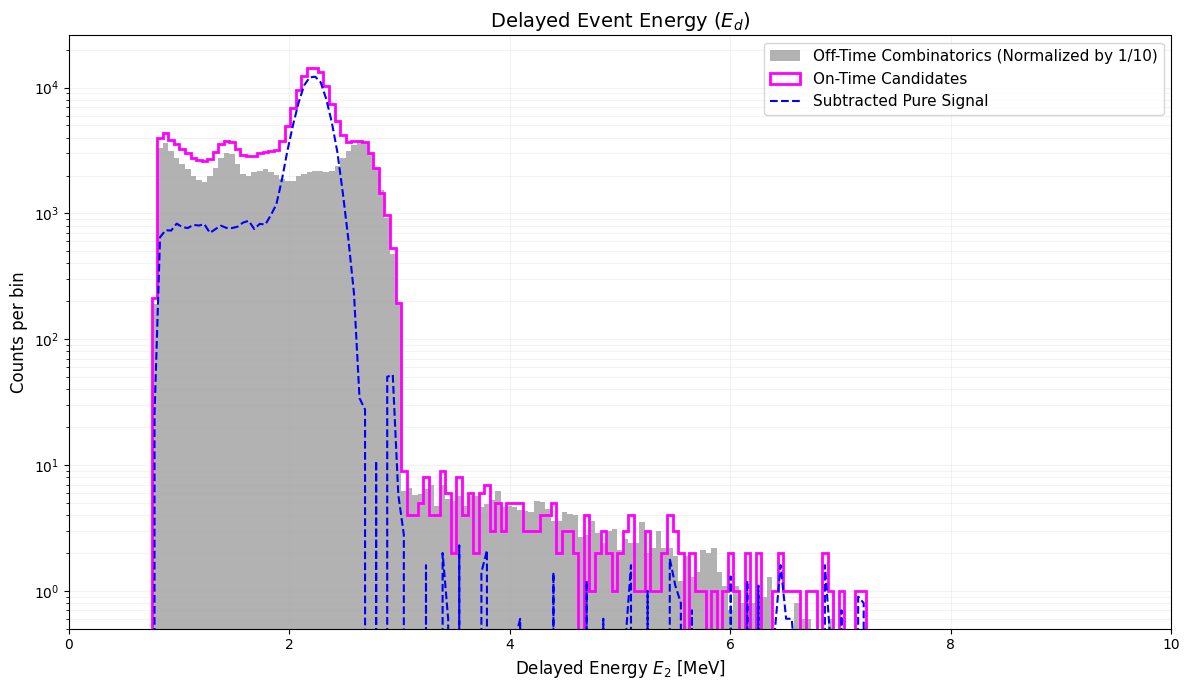

In [11]:
# Execution
plot_delayed_energy(events_df, false_events_df, N_OFF_WINDOWS)

In [12]:
def plot_time_difference(on_df, off_df, n_off_windows=10):
    plt.figure(figsize=(12, 7))
    
    # Convert nanoseconds to microseconds for readability
    on_time_us = on_df['dt_shifted'] / 1000.0
    off_time_us = off_df['dt_shifted'] / 1000.0
    
    # Define bins from 0 to 2000 us (2 ms)
    bins = np.linspace(0, 2000, 200)
    
    # Scale the off-time background by the number of ghost windows
    weights_off = np.ones(len(off_time_us)) / n_off_windows
    
    # Plot Off-Time (Accidental Background)
    plt.hist(off_time_us, bins=bins, weights=weights_off, 
             histtype='stepfilled', color='black', alpha=0.3, 
             label=f'Off-Time Combinatorics (Normalized by 1/{n_off_windows})')
    
    # Plot On-Time (Signal + Background)
    plt.hist(on_time_us, bins=bins, 
             histtype='step', color='magenta', linewidth=2, 
             label='On-Time Candidates')
    
    # Formatting
    plt.title(r'Temporal Phase Space: Shifted Time Difference ($\Delta t$)', fontsize=14)
    plt.xlabel(r'Time Difference $\Delta t_{shifted}$ [$\mu s$]', fontsize=12)
    plt.ylabel('Counts per bin', fontsize=12)
    
    plt.xlim(left=0, right=2000)
    plt.legend(loc='upper right', fontsize=11)
    plt.grid(True, which="both", ls="-", alpha=0.15)
    plt.tight_layout()
    
    plt.show()

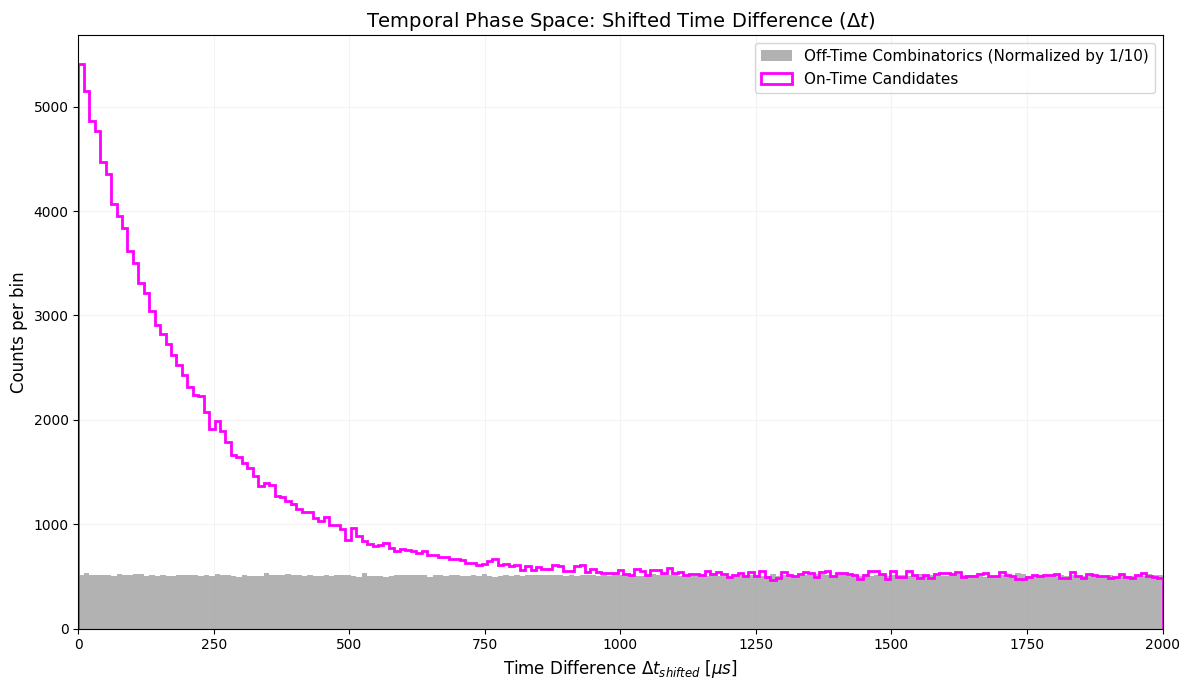

In [13]:
# Execution
plot_time_difference(events_df, false_events_df, N_OFF_WINDOWS)

In [14]:
from matplotlib.colors import LogNorm

def plot_prompt_vs_delayed_energy(df, max_energy=12.0, bins=200):
    plt.figure(figsize=(10, 8))
    
    # Define physical energy bins (e.g., 0 to 12 MeV)
    bins_x = np.linspace(0, max_energy, bins)
    bins_y = np.linspace(0, max_energy, bins)
    
    # Create the 2D histogram with a logarithmic color normalization
    # 'jet' or 'viridis' are standard for this type of high-contrast phase space
    counts, xedges, yedges, im = plt.hist2d(
        df['E_1'], df['E_2'], 
        bins=[bins_x, bins_y], 
        cmap='viridis', 
        norm=LogNorm()
    )
    
    # Formatting
    cbar = plt.colorbar(im)
    cbar.set_label('Number of Events (Log Scale)', fontsize=12, rotation=270, labelpad=20)
    
    plt.title('Calorimetric Phase Space: Prompt vs. Delayed Energy', fontsize=14)
    plt.xlabel('Prompt Energy $E_1$ [MeV]', fontsize=12)
    plt.ylabel('Delayed Energy $E_2$ [MeV]', fontsize=12)
    
    plt.xlim(0, max_energy)
    plt.ylim(0, max_energy)
    
    plt.grid(True, which="both", ls="-", alpha=0.15)
    plt.tight_layout()
    plt.show()

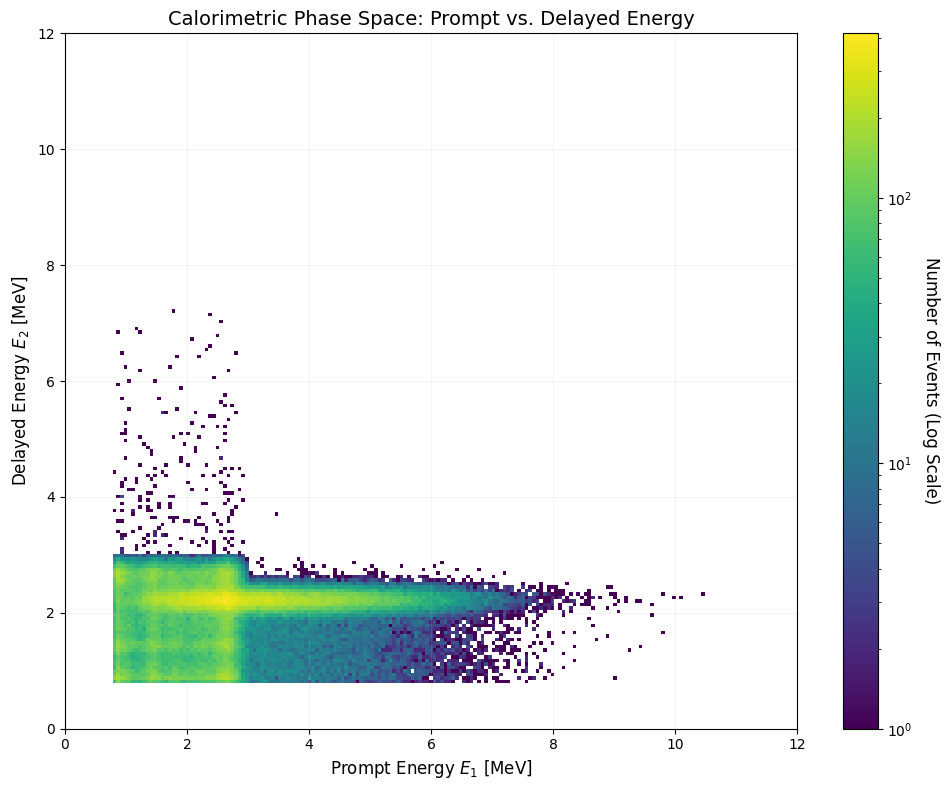

In [15]:
# Execution for the on-time candidates
plot_prompt_vs_delayed_energy(events_df)

In [16]:
def plot_subtracted_phase_space(on_df, off_df, n_off_windows=10, max_energy=12.0, bins=200):
    # 1. Define physical bin edges
    bins_x = np.linspace(0, max_energy, bins + 1)
    bins_y = np.linspace(0, max_energy, bins + 1)
    
    # 2. Compute 2D histograms
    on_counts, xedges, yedges = np.histogram2d(
        on_df['E_1'], on_df['E_2'], bins=[bins_x, bins_y]
    )
    
    # Scale the off-time background by the inverse of the ghost windows
    weights_off = np.ones(len(off_df)) / n_off_windows
    off_counts, _, _ = np.histogram2d(
        off_df['E_1'], off_df['E_2'], bins=[bins_x, bins_y], weights=weights_off
    )
    
    # 3. Matrix Subtraction
    pure_signal_2d = on_counts - off_counts
    
    # 4. Rectify negative Poisson fluctuations for logarithmic plotting
    # We use 1e-3 instead of 0 to ensure absolute compatibility with LogNorm
    pure_signal_clean = np.where(pure_signal_2d > 0, pure_signal_2d, 1e-3)
    
    # 5. Plotting
    plt.figure(figsize=(10, 8))
    
    # pcolormesh maps the grid edges to the bin contents.
    # The transposed matrix (.T) is strictly required because histogram2d 
    # returns shape (nx, ny) but pcolormesh expects (ny, nx) layout.
    X, Y = np.meshgrid(xedges, yedges)
    im = plt.pcolormesh(X, Y, pure_signal_clean.T, cmap='viridis', norm=LogNorm(vmin=1e-1))
    
    cbar = plt.colorbar(im)
    cbar.set_label('Pure Correlated Events (Log Scale)', fontsize=12, rotation=270, labelpad=20)
    
    plt.title('Subtracted Pure Signal Phase Space: Prompt vs. Delayed Energy', fontsize=14)
    plt.xlabel('Prompt Energy $E_1$ [MeV]', fontsize=12)
    plt.ylabel('Delayed Energy $E_2$ [MeV]', fontsize=12)
    
    plt.xlim(0, max_energy)
    plt.ylim(0, max_energy)
    plt.grid(True, which="both", ls="-", alpha=0.15)
    plt.tight_layout()
    plt.show()

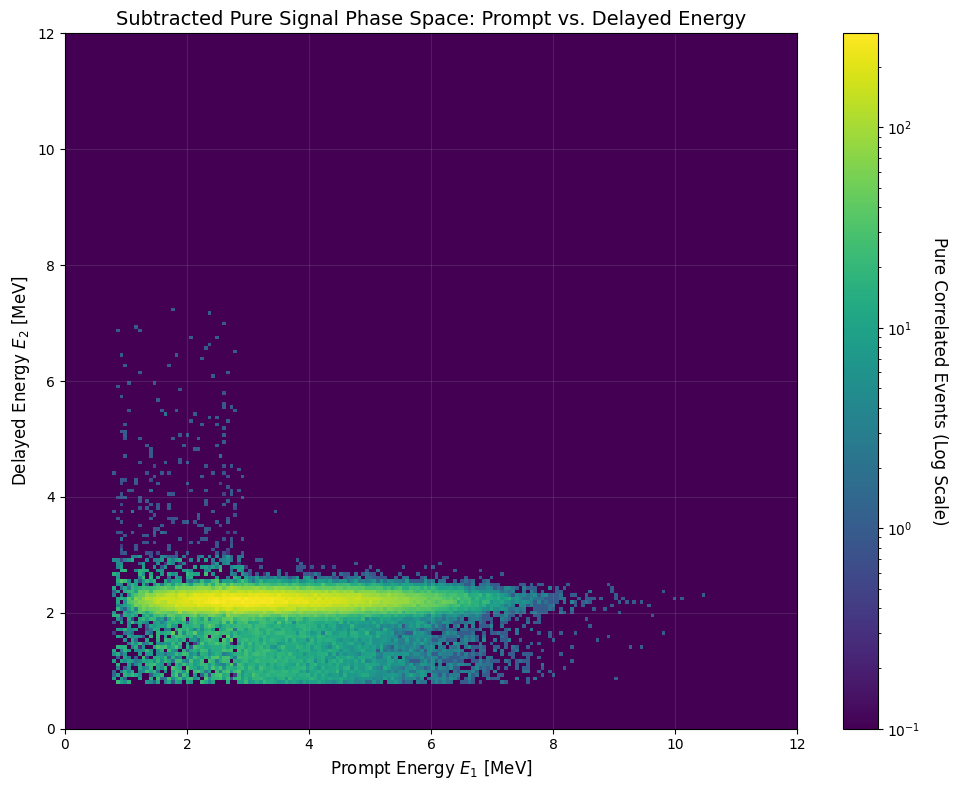

In [17]:
# Execution
plot_subtracted_phase_space(events_df, false_events_df, N_OFF_WINDOWS)